In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn kneed

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Python\pythoncore-3.15-64\python.exe -m pip install --upgrade pip


First Five Rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape:
(100000, 9)

Selected Features:
   gender   age  hypertension  heart_disease  smoking_history    bmi  \
0       0  80.0             0              1                4  25.19   
1       0  54.0             0              0                0  27.32   
2   

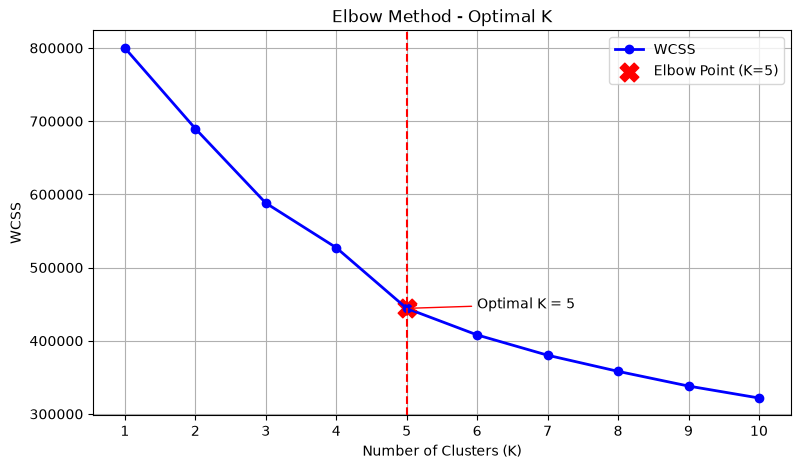


Clustered Dataset:
   gender   age  hypertension  heart_disease  smoking_history    bmi  \
0       0  80.0             0              1                4  25.19   
1       0  54.0             0              0                0  27.32   
2       1  28.0             0              0                4  27.32   
3       0  36.0             0              0                1  23.45   
4       1  76.0             1              1                1  20.14   

   HbA1c_level  blood_glucose_level  diabetes  Cluster  
0          6.6                  140         0        4  
1          6.6                   80         0        1  
2          5.7                  158         0        0  
3          5.0                  155         0        1  
4          4.8                  155         0        4  


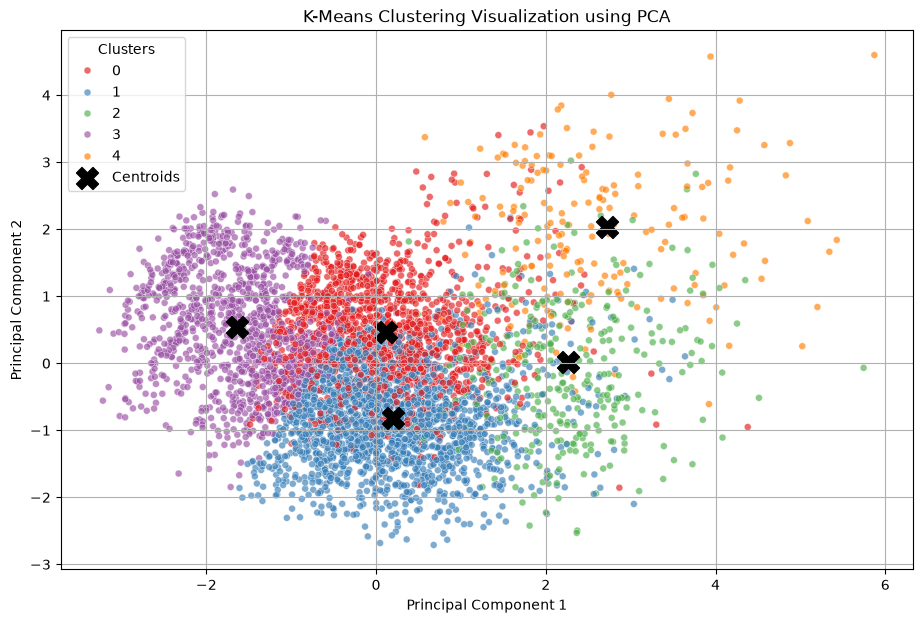


Cluster Centers:
         gender        age  hypertension  heart_disease  smoking_history  \
0  1.000671e+00  47.522106 -6.522560e-15   2.997602e-15         2.493791   
1  8.332224e-14  47.704000  9.492407e-15   8.375245e-15         2.851616   
2  4.209164e-01  60.728878  1.000000e+00  -1.637579e-15         2.818237   
3  4.244620e-01  14.517931 -5.870304e-15  -2.775558e-16         0.357625   
4  6.037544e-01  67.823440  2.323694e-01   1.000000e+00         2.437088   

         bmi  HbA1c_level  blood_glucose_level  
0  28.702593     5.559635           139.482864  
1  28.723232     5.521163           137.745294  
2  30.879703     5.805435           149.481656  
3  21.733842     5.355737           131.072921  
4  29.325700     5.884729           152.137747  

Number of Records in Each Cluster:
Cluster
0    26801
1    40382
2     6569
3    22306
4     3942
Name: count, dtype: int64

Final WCSS: 444271.0122058989

K-Means Clustering Completed Successfully!


In [3]:

# K-MEANS CLUSTERING
# Diabetes Prediction Dataset
# Applying K-Means, Elbow Method and Cluster Visualization

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from kneed import KneeLocator

# Step 2: Load Dataset

df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# Step 3: Handle Missing Values

df = df.dropna().copy()

# Step 4: Convert Categorical Data into Numerical Data

df['gender'] = df['gender'].astype('category').cat.codes
df['smoking_history'] = df['smoking_history'].astype('category').cat.codes

# Step 5: Select Input Features

# Remove diabetes column because K-Means is unsupervised

X = df.drop('diabetes', axis=1)

print("\nSelected Features:")
print(X.head())

# Step 6: Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 7: Elbow Method

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Find Elbow Point Automatically

knee = KneeLocator(
    range(1, 11),
    wcss,
    curve='convex',
    direction='decreasing'
)

optimal_k = knee.elbow

print("\nOptimal Number of Clusters:", optimal_k)

# Step 8: Visualize Elbow Graph

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    color='blue',
    linewidth=2,
    label='WCSS'
)

if optimal_k is not None:

    plt.scatter(
        optimal_k,
        wcss[optimal_k - 1],
        color='red',
        s=180,
        marker='X',
        label=f'Elbow Point (K={optimal_k})'
    )

    plt.axvline(
        x=optimal_k,
        color='red',
        linestyle='--'
    )

    plt.annotate(
        f'Optimal K = {optimal_k}',
        xy=(optimal_k, wcss[optimal_k - 1]),
        xytext=(optimal_k + 1, wcss[optimal_k - 1]),
        arrowprops=dict(arrowstyle='->', color='red')
    )

else:
    print("No clear elbow found. Please inspect the graph.")

plt.title("Elbow Method - Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.legend()
plt.show()

# Step 9: Apply K-Means Clustering

# If automatic elbow is not detected, use K=3 as a fallback

if optimal_k is None:
    optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nClustered Dataset:")
print(df.head())

# Step 10: Apply PCA for 2D Visualization

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create visualization dataframe

plot_df = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': df['Cluster'].values
})

# Step 11: Visualize Clusters

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_df.sample(
        n=min(5000, len(plot_df)),
        random_state=42
    ),
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=25,
    alpha=0.65
)

# Display Cluster Centers

centers_pca = pca.transform(kmeans.cluster_centers_)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    color='black',
    marker='X',
    s=250,
    label='Centroids'
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Clusters")
plt.grid(True)
plt.show()

# Step 12: Display Cluster Centers

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    centers,
    columns=X.columns
)

print("\nCluster Centers:")
print(centers_df)

# Step 13: Count Records in Each Cluster

print("\nNumber of Records in Each Cluster:")

print(
    df['Cluster'].value_counts().sort_index()
)

# Step 14: Display WCSS

print("\nFinal WCSS:", kmeans.inertia_)

print("\nK-Means Clustering Completed Successfully!")
